In [3]:
%pip install openpyxl


[notice] A new release of pip is available: 24.3.1 -> 26.1.2
[notice] To update, run: python3 -m pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ==========================================
# 1. Load the Data
# ==========================================
movies_df = pd.read_csv("movies.csv")
ratings_df = pd.read_excel("ratings.xlsx")

In [5]:
# ==========================================
# 2. Merge Datasets
# ==========================================
# Inner Join: Keeps rows with matching movieId in both
inner_merged = pd.merge(ratings_df, movies_df, on="movieId", how="inner")

# Left Join: Keeps all rows from ratings_df
left_merged = pd.merge(ratings_df, movies_df, on="movieId", how="left")

# Right Join: Keeps all rows from movies_df
right_merged = pd.merge(ratings_df, movies_df, on="movieId", how="right")

# Outer Join: Includes all rows from both datasets
outer_merged = pd.merge(ratings_df, movies_df, on="movieId", how="outer")

# We will use inner_merged for subsequent transformation steps
df_transformed = inner_merged.copy()

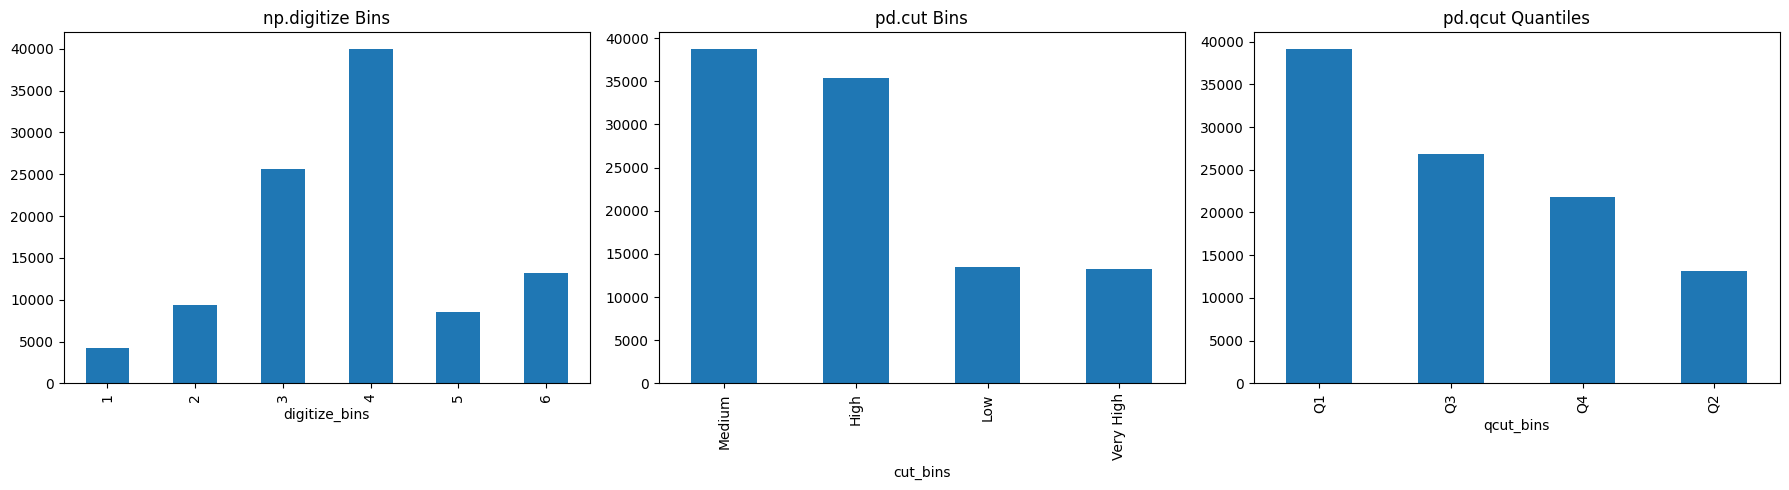

In [6]:
# ==========================================
# 3. Transform the Data
# ==========================================
# np.digitize(): Binning into 5 predefined bins (e.g., 0.5-1.5, 1.5-2.5, etc.)
# Assuming standard MovieLens ratings from 0.5 to 5.0
bins = [0, 1.5, 2.5, 3.5, 4.5, 5.0]
df_transformed["digitize_bins"] = np.digitize(df_transformed["rating"], bins)

# pd.cut(): Custom bins with categorical labels
cut_bins = [0, 2.0, 3.5, 4.5, 5.0]
cut_labels = ["Low", "Medium", "High", "Very High"]
df_transformed["cut_bins"] = pd.cut(
    df_transformed["rating"], bins=cut_bins, labels=cut_labels
)

# pd.qcut(): Split into equal-sized quantiles (Quartiles: Q1, Q2, Q3, Q4)
# duplicates='drop' is often used if discrete rating values overlap at quantile boundaries
df_transformed["qcut_bins"] = pd.qcut(
    df_transformed["rating"], q=4, labels=["Q1", "Q2", "Q3", "Q4"]
)

# OPTIONAL: Plot each output
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
df_transformed["digitize_bins"].value_counts().sort_index().plot(
    kind="bar", ax=axes[0], title="np.digitize Bins"
)
df_transformed["cut_bins"].value_counts().plot(
    kind="bar", ax=axes[1], title="pd.cut Bins"
)
df_transformed["qcut_bins"].value_counts().plot(
    kind="bar", ax=axes[2], title="pd.qcut Quantiles"
)
plt.tight_layout()
plt.show()

In [7]:
# ==========================================
# 4. Handling Missing Data
# ==========================================
# Creating a copy to demonstrate different filling strategies
df_fill_zero = df_transformed.copy()
df_fill_mean_mode = df_transformed.copy()

# Option A: Fill missing values with 0
df_fill_zero["rating"] = df_fill_zero["rating"].fillna(0)

# Option B: Fill missing values with the mean (for numeric) or mode (for categorical/object)
rating_mean = df_fill_mean_mode["rating"].mean()
df_fill_mean_mode["rating"] = df_fill_mean_mode["rating"].fillna(rating_mean)

# Handling other possible missing columns with mode
for col in df_fill_mean_mode.columns:
    if df_fill_mean_mode[col].isnull().any():
        df_fill_mean_mode[col] = df_fill_mean_mode[col].fillna(
            df_fill_mean_mode[col].mode()[0]
        )

In [8]:
# ==========================================
# 5. Stack and Unstack
# ==========================================
# Create a small pivot table to easily visualize wide vs long format
pivot_df = df_fill_mean_mode.pivot_table(
    index="title", columns="userId", values="rating"
).head(10)

# Stack: Move the columns (userId) to rows, making it long format
stacked_df = pivot_df.stack()
print("--- Stacked DataFrame ---")
print(stacked_df.head())

# Unstack: Restore the DataFrame back to its original wide format
unstacked_df = stacked_df.unstack()
print("\n--- Unstacked DataFrame ---")
print(unstacked_df.head())

--- Stacked DataFrame ---
title                                    userId
'71 (2014)                               610       4.0
'Hellboy': The Seeds of Creation (2004)  332       4.0
'Round Midnight (1986)                   332       3.5
                                         377       3.5
'Salem's Lot (2004)                      345       5.0
dtype: float64

--- Unstacked DataFrame ---
userId                                   610  332  377  345  113  21   12   \
title                                                                        
'71 (2014)                               4.0  NaN  NaN  NaN  NaN  NaN  NaN   
'Hellboy': The Seeds of Creation (2004)  NaN  4.0  NaN  NaN  NaN  NaN  NaN   
'Round Midnight (1986)                   NaN  3.5  3.5  NaN  NaN  NaN  NaN   
'Salem's Lot (2004)                      NaN  NaN  NaN  5.0  NaN  NaN  NaN   
'Til There Was You (1997)                NaN  NaN  NaN  5.0  3.0  NaN  NaN   

userId                                   19   91   95   ... 

In [9]:
# ==========================================
# 6. Find Most Rated Genres
# ==========================================
# Step 1: Ensure we are using a dataframe with clean movie and rating data
# Step 2: Split the genres column by '|' and explode it into multiple rows
df_genres = df_fill_mean_mode.copy()
df_genres["genres"] = df_genres["genres"].str.split("|")
df_exploded = df_genres.explode("genres")

# Step 3: Count total occurrences of each genre (highest number of ratings overall)
genre_counts = df_exploded["genres"].value_counts()
most_rated_genre = genre_counts.idxmax()
highest_count = genre_counts.max()

print("\n--- Genre Ranking by Total Ratings ---")
print(genre_counts)
print(
    f"\nThe most rated genre is '{most_rated_genre}' with {highest_count} ratings."
)


--- Genre Ranking by Total Ratings ---
genres
Drama                 41928
Comedy                39053
Action                30635
Thriller              26452
Adventure             24161
Romance               18124
Sci-Fi                17243
Crime                 16681
Fantasy               11834
Children               9208
Mystery                7674
Horror                 7291
Animation              6988
War                    4859
IMAX                   4145
Musical                4138
Western                1930
Documentary            1219
Film-Noir               870
(no genres listed)       47
Name: count, dtype: int64

The most rated genre is 'Drama' with 41928 ratings.
